# H2O AutoML aplicado a la serie de radiación solar — Pronóstico a 24 horas y a 1 semana

Versión para ejecutar directamente, celda por celda, desde Jupyter Notebook o JupyterLab.

A diferencia de la versión original (que pronosticaba únicamente el siguiente intervalo de 15 minutos), este notebook entrena y evalúa **dos modelos independientes**:

- **Horizonte de 24 horas** → 96 pasos de 15 minutos hacia adelante.
- **Horizonte de 1 semana** → 672 pasos de 15 minutos hacia adelante.

Todos los gráficos y métricas de cada horizonte se guardan automáticamente en carpetas separadas dentro de `resultados_h2o_radiacion/`:

```
resultados_h2o_radiacion/
├── 24h/
│   ├── graficos/
│   ├── metricas/
│   └── modelos/
├── 7d/
│   ├── graficos/
│   ├── metricas/
│   └── modelos/
└── comparacion_horizontes.csv
```

No requiere SLURM.

## 1. Instalación de librerías
Ejecutar esta celda solamente si las librerías no están instaladas.

In [1]:
%pip install -q h2o pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 2. Carga de librerías

In [2]:
import os
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import h2o
from h2o.automl import H2OAutoML
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')

## 3. Carga de la base de radiación

In [4]:
RUTA_DATOS = 'unificada.csv'  # Cambiar si el archivo está en otra carpeta
df = pd.read_csv(RUTA_DATOS, sep=';', low_memory=False)
df.head()

,fecha,temperatura,humedad,presion,radiacion,precipitacion,precipitacion_acum_diaria,veloc_de_viento_max_10m,veloc_de_viento_min_10m,veloc_de_viento_prom_10m,direccion_de_viento_a_10m,direccion_a_10m,veloc_de_viento_max_2m,veloc_de_viento_min_2m,veloc_de_viento_prom_2m,direccion_de_viento_a_2m,direccion_a_2m,evaporimetro,evaporacion_acum_diaria
0,18/8/2016 01:00,NaN,24.2,954.5,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1,18/8/2016 01:15,18.9,24.0,954.5,0.0,0.0,0.0,44.8,0.0,26.7,13.3,NaN,33.1,0.0,17.7,23.6,NaN,NaN,NaN
2,18/8/2016 01:30,19.0,23.6,954.5,0.0,0.0,0.0,46.6,0.0,27.5,14.2,NaN,30.4,0.0,17.7,23.6,NaN,NaN,NaN
3,18/8/2016 01:45,19.1,23.4,954.5,0.0,0.0,0.0,49.3,0.0,28.1,12.2,NaN,34.9,0.0,18.4,20.8,NaN,NaN,NaN
4,18/8/2016 02:00,19.0,23.4,954.5,0.0,0.0,0.0,42.1,0.0,26.1,15.2,NaN,29.5,0.0,17.3,23.2,NaN,NaN,NaN


## 4. Análisis exploratorio general

In [5]:
print('Dimensión:', df.shape)
df.info()

Dimensión: (336767, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336767 entries, 0 to 336766
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   fecha                      336767 non-null  object 
 1   temperatura                336642 non-null  float64
 2   humedad                    336666 non-null  float64
 3   presion                    335006 non-null  float64
 4   radiacion                  336702 non-null  object 
 5   precipitacion              336728 non-null  float64
 6   precipitacion_acum_diaria  335911 non-null  float64
 7   veloc_de_viento_max_10m    336767 non-null  float64
 8   veloc_de_viento_min_10m    336767 non-null  float64
 9   veloc_de_viento_prom_10m   336767 non-null  float64
 10  direccion_de_viento_a_10m  336610 non-null  float64
 11  direccion_a_10m            290846 non-null  object 
 12  veloc_de_viento_max_2m     336767 non-null  object 
 13  veloc

In [6]:
# Conversión de fecha y columnas numéricas
df['fecha'] = pd.to_datetime(df['fecha'], dayfirst=True, errors='coerce')
variables = [
    'radiacion', 'temperatura', 'humedad', 'presion', 'precipitacion',
    'precipitacion_acum_diaria', 'veloc_de_viento_prom_10m',
    'veloc_de_viento_prom_2m'
]
variables = [c for c in variables if c in df.columns]
for c in variables:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.', regex=False), errors='coerce')

df = (df.dropna(subset=['fecha'])
        .sort_values('fecha')
        .drop_duplicates('fecha', keep='last')
        .set_index('fecha'))
df[variables].describe().T

,count,mean,std,min,25%,50%,75%,max
radiacion,336464.0,192.934876,278.726192,0.0,0.0,1.5,360.6,999.8
temperatura,336639.0,21.510030,7.905230,-38.3,16.1,22.0,27.3,44.8
humedad,336663.0,49.399627,20.569982,1.0,32.6,47.9,63.9,100.0
presion,335003.0,951.621044,12.233353,25.3,947.8,951.6,955.8,974.6
precipitacion,336725.0,0.013428,0.270754,0.0,0.0,0.0,0.0,90.7
precipitacion_acum_diaria,335908.0,0.708566,4.069848,0.0,0.0,0.0,0.0,90.7
veloc_de_viento_prom_10m,336764.0,11.559930,8.957427,0.0,4.0,9.9,18.3,61.4
veloc_de_viento_prom_2m,336764.0,7.335422,6.521024,0.0,1.0,6.1,12.1,44.3


In [7]:
calidad = pd.DataFrame({
    'tipo': df[variables].dtypes.astype(str),
    'faltantes': df[variables].isna().sum(),
    'porcentaje_faltante': df[variables].isna().mean().mul(100).round(2)
})
calidad

,tipo,faltantes,porcentaje_faltante
radiacion,float64,300,0.09
temperatura,float64,125,0.04
humedad,float64,101,0.03
presion,float64,1761,0.52
precipitacion,float64,39,0.01
precipitacion_acum_diaria,float64,856,0.25
veloc_de_viento_prom_10m,float64,0,0.00
veloc_de_viento_prom_2m,float64,0,0.00


## 5. Visualización de la radiación y las variables meteorológicas

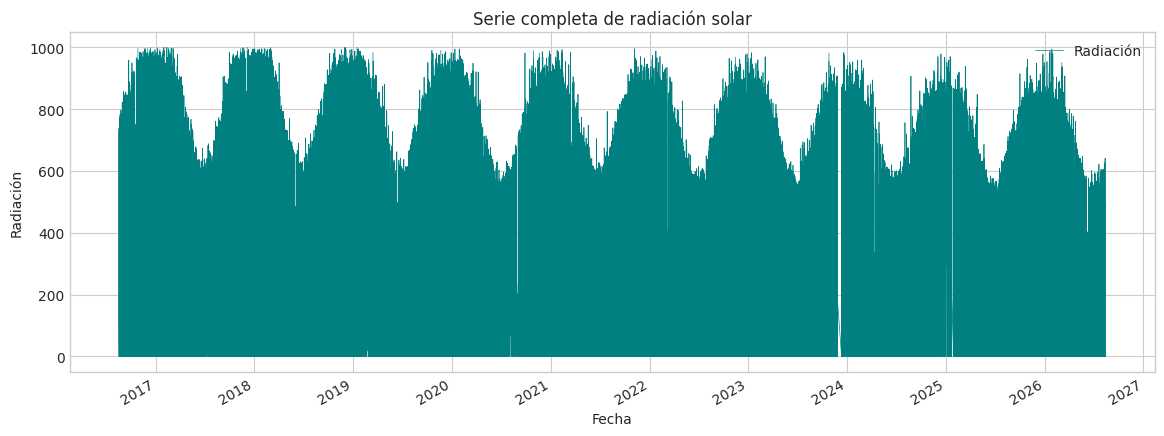

In [8]:
ax = df['radiacion'].plot(label='Radiación', color='teal', figsize=(14, 5), lw=0.5)
ax.set(title='Serie completa de radiación solar', xlabel='Fecha', ylabel='Radiación')
plt.legend();
plt.show()

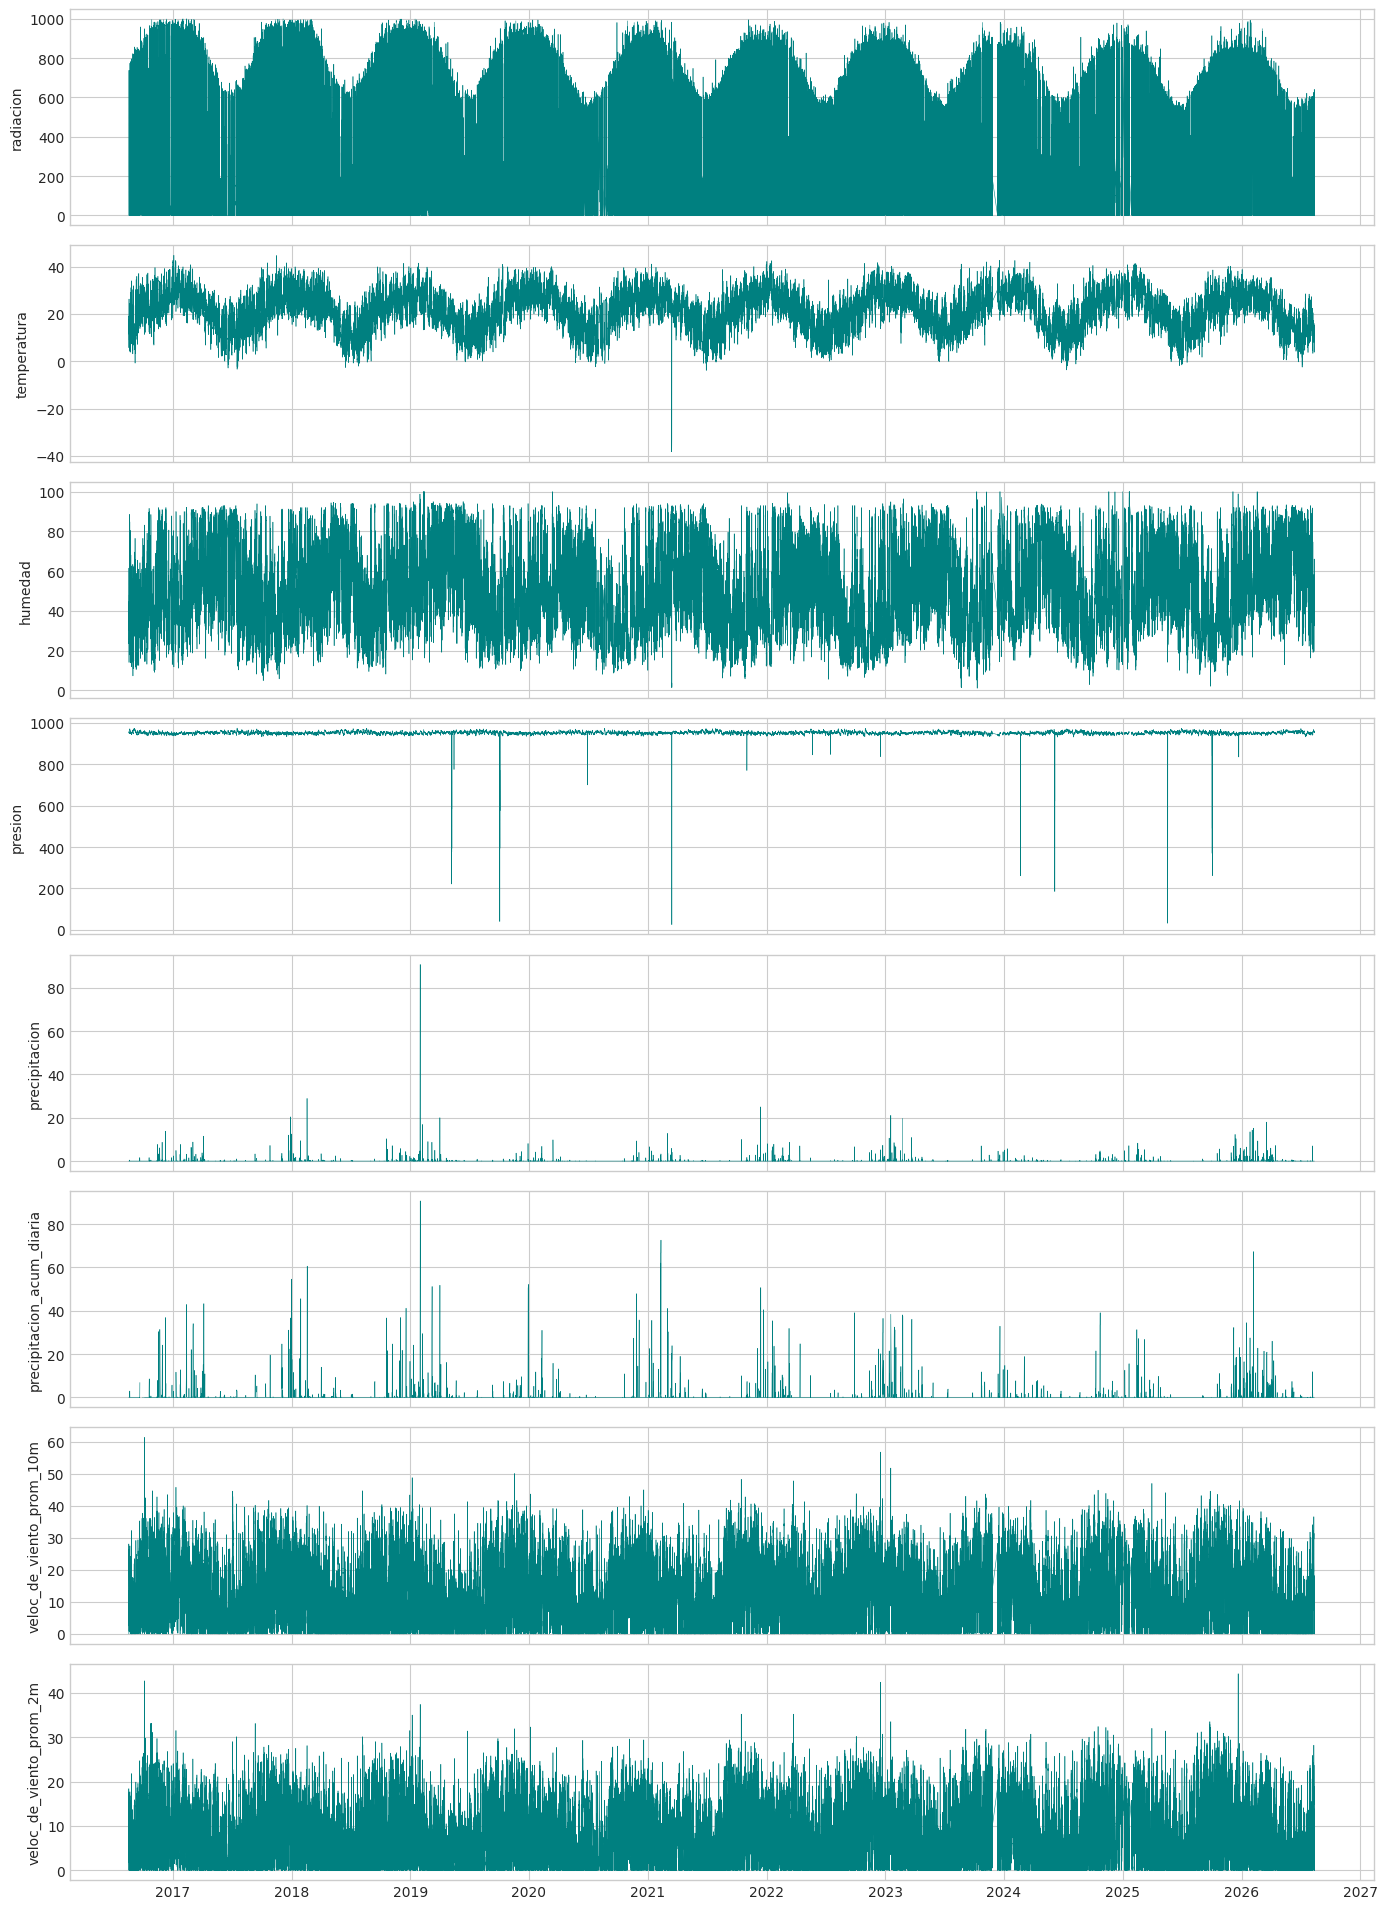

In [9]:
columnas_grafico = [c for c in variables if c in df.columns]
fig, axes = plt.subplots(len(columnas_grafico), 1, figsize=(14, 2.4*len(columnas_grafico)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), columnas_grafico):
    ax.plot(df.index, df[c], color='teal', lw=0.4)
    ax.set_ylabel(c)
plt.tight_layout();
plt.show()

## 6. Matriz de correlación

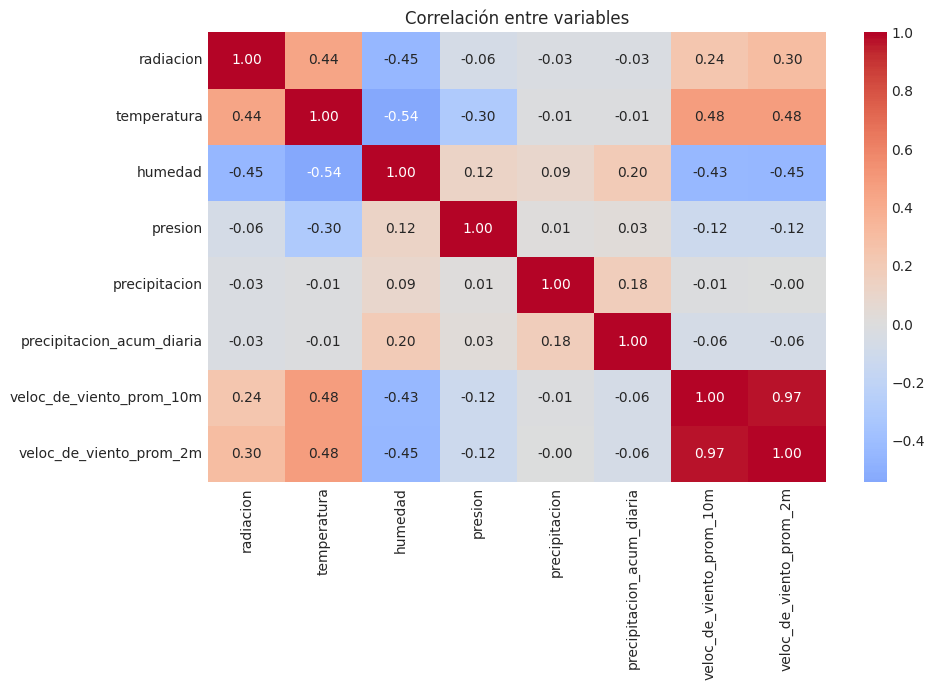

In [10]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[variables].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlación entre variables')
plt.tight_layout();
plt.show()

## 7. Regularización de la frecuencia
Se reconstruye la frecuencia exacta de 15 minutos para que los retardos y los horizontes de pronóstico representen siempre el mismo intervalo de tiempo real.

In [11]:
df_modelo = df[variables].copy()
indice_regular = pd.date_range(df_modelo.index.min(), df_modelo.index.max(), freq='15min')
df_modelo = df_modelo.reindex(indice_regular)
df_modelo.index.name = 'fecha'

exogenas = [c for c in variables if c != 'radiacion']
df_modelo[exogenas] = df_modelo[exogenas].interpolate(
    method='time', limit=4, limit_direction='both'
)
df_modelo.loc[df_modelo['radiacion'] < 0, 'radiacion'] = np.nan
print('Período:', df_modelo.index.min(), 'a', df_modelo.index.max())
print('Filas regulares:', len(df_modelo))

Período: 2016-08-18 01:00:00 a 2026-08-12 22:15:00
Filas regulares: 350102


## 8. Conversión de la serie temporal en aprendizaje supervisado (parametrizada por horizonte)

La función ahora recibe `horizonte_pasos`: la cantidad de intervalos de 15 minutos hacia adelante que se desea pronosticar.

- 24 horas = 96 pasos
- 1 semana = 672 pasos

Los retardos, medias móviles y variables exógenas siguen calculándose con información disponible hasta el instante `t`; sólo cambia qué tan lejos en el futuro se ubica el objetivo `radiacion_t_mas_h`.

In [12]:
def preparar_serie_supervisada(datos, horizonte_pasos, exogenas):
    salida = pd.DataFrame(index=datos.index)
    salida['radiacion_t'] = datos['radiacion']

    # Retardos: 15 min, 1 hora, 1 día, 2 días y 1 semana (información conocida en t)
    for lag in [1, 4, 96, 192, 672]:
        salida[f'radiacion_lag_{lag}'] = datos['radiacion'].shift(lag)

    # Medias y dispersiones móviles calculadas sin información futura
    for ventana in [4, 12, 96]:
        minimo = max(2, ventana // 2)
        salida[f'radiacion_media_{ventana}'] = datos['radiacion'].rolling(ventana, min_periods=minimo).mean()
        salida[f'radiacion_std_{ventana}'] = datos['radiacion'].rolling(ventana, min_periods=minimo).std()

    for c in exogenas:
        salida[f'{c}_t'] = datos[c]
        salida[f'{c}_lag_1'] = datos[c].shift(1)

    # Variables de calendario del instante futuro que se desea pronosticar
    fecha_futura = salida.index + pd.Timedelta(minutes=15 * horizonte_pasos)
    minutos = fecha_futura.hour * 60 + fecha_futura.minute
    salida['hora_sin'] = np.sin(2*np.pi*minutos/1440)
    salida['hora_cos'] = np.cos(2*np.pi*minutos/1440)
    salida['dia_anio_sin'] = np.sin(2*np.pi*fecha_futura.dayofyear/365.25)
    salida['dia_anio_cos'] = np.cos(2*np.pi*fecha_futura.dayofyear/365.25)
    salida['mes'] = fecha_futura.month
    salida['dia_semana'] = fecha_futura.dayofweek

    columna_objetivo = f'radiacion_t_mas_{horizonte_pasos}'
    salida[columna_objetivo] = datos['radiacion'].shift(-horizonte_pasos)
    salida = salida.replace([np.inf, -np.inf], np.nan).dropna()
    return salida, columna_objetivo


def calcular_metricas(real, predicho):
    real = np.asarray(real, dtype=float)
    predicho = np.asarray(predicho, dtype=float)
    mascara = np.abs(real) > 1e-8
    return {
        'MAE': mean_absolute_error(real, predicho),
        'RMSE': np.sqrt(mean_squared_error(real, predicho)),
        'R2': r2_score(real, predicho),
        'MAPE_sin_ceros_pct': np.mean(np.abs((real[mascara]-predicho[mascara])/real[mascara]))*100
    }

## 9. Carpetas de resultados

Se crea, para cada horizonte, una subcarpeta con `graficos/`, `metricas/` y `modelos/`.

In [13]:
BASE_RESULTADOS = 'resultados_h2o_radiacion'

def crear_carpetas(nombre_horizonte):
    base = os.path.join(BASE_RESULTADOS, nombre_horizonte)
    carpetas = {
        'base': base,
        'graficos': os.path.join(base, 'graficos'),
        'metricas': os.path.join(base, 'metricas'),
        'modelos': os.path.join(base, 'modelos'),
    }
    for ruta in carpetas.values():
        os.makedirs(ruta, exist_ok=True)
    return carpetas

## 10. Inicialización de H2O

In [14]:
# Configuración para una computadora personal.
# Si dispone de poca memoria, cambiar MEMORIA_H2O a '4G'.
# Si dispone de 16 GB de RAM o más, puede conservar '8G'.
MEMORIA_H2O = '8G'
N_HILOS = 4
h2o.init(nthreads=N_HILOS, max_mem_size=MEMORIA_H2O)

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "17.0.18-internal" 2026-01-20; OpenJDK Runtime Environment (build 17.0.18-internal+0-adhoc.conda.src); OpenJDK 64-Bit Server VM (build 17.0.18-internal+0-adhoc.conda.src, mixed mode, sharing)
  Starting server from /home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpdh0b2zau
  JVM stdout: /tmp/tmpdh0b2zau/h2o_csosach_started_from_python.out
  JVM stderr: /tmp/tmpdh0b2zau/h2o_csosach_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,America/Argentina/Catamarca
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,1 month and 15 days
H2O_cluster_name:,H2O_from_python_csosach_wwvmix
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,8 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


## 11. Función de entrenamiento y evaluación por horizonte

Esta función ejecuta, para un horizonte dado, todo el flujo: preparación de datos, separación cronológica, entrenamiento con H2O AutoML, evaluación, gráficos y guardado de resultados en la carpeta correspondiente.

In [15]:
TIEMPO_MAX_SEGUNDOS = 600  # 10 minutos de entrenamiento por horizonte (ajustar según necesidad)
MAX_MODELOS = 10

def entrenar_evaluar_horizonte(horizonte_pasos, nombre_horizonte, etiqueta):
    print(f'=== Horizonte: {etiqueta} ({horizonte_pasos} pasos de 15 min) ===')
    carpetas = crear_carpetas(nombre_horizonte)

    # --- Preparación de datos supervisados para este horizonte ---
    df_h, y = preparar_serie_supervisada(df_modelo, horizonte_pasos, exogenas)
    print(f'[{nombre_horizonte}] Filas utilizables:', len(df_h))

    # --- Separación cronológica en entrenamiento, validación y prueba ---
    n = len(df_h)
    corte_train = int(n * 0.70)
    corte_val = int(n * 0.85)
    df_train = df_h.iloc[:corte_train].copy()
    df_val = df_h.iloc[corte_train:corte_val].copy()
    df_test = df_h.iloc[corte_val:].copy()
    print(f'[{nombre_horizonte}] Entrenamiento:', df_train.shape, df_train.index.min(), df_train.index.max())
    print(f'[{nombre_horizonte}] Validación:', df_val.shape, df_val.index.min(), df_val.index.max())
    print(f'[{nombre_horizonte}] Prueba:', df_test.shape, df_test.index.min(), df_test.index.max())

    plt.figure(figsize=(14, 5))
    plt.plot(df_train.index, df_train[y], label='Train', lw=0.4)
    plt.plot(df_val.index, df_val[y], label='Validación', lw=0.4)
    plt.plot(df_test.index, df_test[y], label='Test', lw=0.4)
    plt.ylabel(f'Radiación objetivo ({etiqueta})')
    plt.title(f'División cronológica de la serie - {etiqueta}')
    plt.legend();
    plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'division_train_val_test.png'), dpi=150)
    plt.show()
    plt.close()

    # --- Conversión a H2OFrame ---
    hf_train = h2o.H2OFrame(df_train.reset_index(drop=True))
    hf_val = h2o.H2OFrame(df_val.reset_index(drop=True))
    hf_test = h2o.H2OFrame(df_test.reset_index(drop=True))

    X = [c for c in hf_train.columns if c != y]
    print(f'[{nombre_horizonte}] Objetivo:', y, '| Cantidad de predictores:', len(X))

    # --- Entrenamiento con H2O AutoML ---
    aml = H2OAutoML(
        nfolds=0,
        max_runtime_secs=TIEMPO_MAX_SEGUNDOS,
        max_models=MAX_MODELOS,
        seed=42,
        sort_metric='RMSE',
        stopping_metric='RMSE',
        verbosity='info',
        exclude_algos=['DeepLearning', 'StackedEnsemble']
    )
    aml.train(x=X, y=y, training_frame=hf_train, validation_frame=hf_val, leaderboard_frame=hf_val)

    leaderboard = aml.leaderboard.as_data_frame()
    leaderboard.to_csv(os.path.join(carpetas['metricas'], 'leaderboard.csv'), index=False)

    leader_model = aml.leader
    print(f'[{nombre_horizonte}] Modelo ganador:', leader_model.model_id)

    # --- Predicción sobre test ---
    hf_test_predict = leader_model.predict(hf_test)
    predicciones = hf_test_predict.as_data_frame()['predict'].to_numpy()
    reales = df_test[y].to_numpy()

    df_results = pd.DataFrame({
        'fecha_objetivo': df_test.index + pd.Timedelta(minutes=15 * horizonte_pasos),
        'radiacion_real': reales,
        'radiacion_predicha': predicciones,
        'error': reales - predicciones
    })
    df_results.to_csv(os.path.join(carpetas['metricas'], 'predicciones_test.csv'), index=False)

    # --- Métricas ---
    metricas_generales = calcular_metricas(reales, predicciones)
    mascara_dia = reales > 20
    metricas_diurnas = calcular_metricas(reales[mascara_dia], predicciones[mascara_dia])
    tabla_metricas = pd.DataFrame(
        [metricas_generales, metricas_diurnas],
        index=['test_completo', 'radiacion_mayor_20']
    )
    tabla_metricas.to_csv(os.path.join(carpetas['metricas'], 'metricas.csv'))
    print(f'[{nombre_horizonte}] Métricas:')
    display(tabla_metricas)

    # --- Gráfico de dispersión ---
    plt.figure(figsize=(7, 6))
    plt.scatter(df_results['radiacion_predicha'], df_results['radiacion_real'], s=3, alpha=0.35, color='red')
    limite = max(df_results['radiacion_real'].max(), df_results['radiacion_predicha'].max())
    plt.plot([0, limite], [0, limite], '--', color='black', label='Predicción perfecta')
    plt.xlabel('Radiación predicha')
    plt.ylabel('Radiación real')
    plt.title(f"Real vs predicha ({etiqueta}) - R² = {metricas_generales['R2']:.3f}")
    plt.legend();
    plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'dispersion_real_vs_predicha.png'), dpi=150)
    plt.show()
    plt.close()

    # --- Gráfico temporal ---
    puntos_visibles = 96 * 30 if horizonte_pasos <= 96 else 96 * 180
    grafico = df_results.tail(min(puntos_visibles, len(df_results)))
    plt.figure(figsize=(15, 5))
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_real'], label='Real', lw=1)
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_predicha'], label='Predicha', lw=1)
    plt.title(f"Predicción H2O AutoML ({etiqueta}) - RMSE = {metricas_generales['RMSE']:.2f}")
    plt.xlabel('Fecha')
    plt.ylabel('Radiación')
    plt.legend();
    plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'serie_temporal_predicciones.png'), dpi=150)
    plt.show()
    plt.close()

    # --- Importancia de variables ---
    try:
        importancia = leader_model.varimp(use_pandas=True)
        importancia.to_csv(os.path.join(carpetas['metricas'], 'importancia_variables.csv'), index=False)
        importancia.head(20).sort_values('relative_importance').plot.barh(
            x='variable', y='relative_importance', figsize=(9, 7), legend=False
        )
        plt.title(f'Importancia de las variables ({etiqueta})')
        plt.tight_layout()
        plt.savefig(os.path.join(carpetas['graficos'], 'importancia_variables.png'), dpi=150)
        plt.show()
        plt.close()
    except Exception as e:
        print(f'[{nombre_horizonte}] El algoritmo ganador no ofrece importancia de variables:', e)

    # --- Guardado del modelo ---
    ruta_modelo = h2o.save_model(leader_model, path=os.path.abspath(carpetas['modelos']), force=True)
    print(f'[{nombre_horizonte}] Modelo guardado en:', ruta_modelo)

    return {'horizonte': nombre_horizonte, 'pasos_15min': horizonte_pasos, 'modelo_ganador': leader_model.model_id, **metricas_generales}

## 12. Ejecución — pronóstico a 24 horas

96 pasos de 15 minutos hacia adelante.

=== Horizonte: Radiación a 24 horas (96 pasos de 15 min) ===
[24h] Filas utilizables: 303466
[24h] Entrenamiento: (212426, 33) 2016-08-25 01:00:00 2023-08-26 02:00:00
[24h] Validación: (45520, 33) 2023-08-26 02:15:00 2025-03-20 02:45:00
[24h] Prueba: (45520, 33) 2025-03-20 03:00:00 2026-08-11 22:15:00


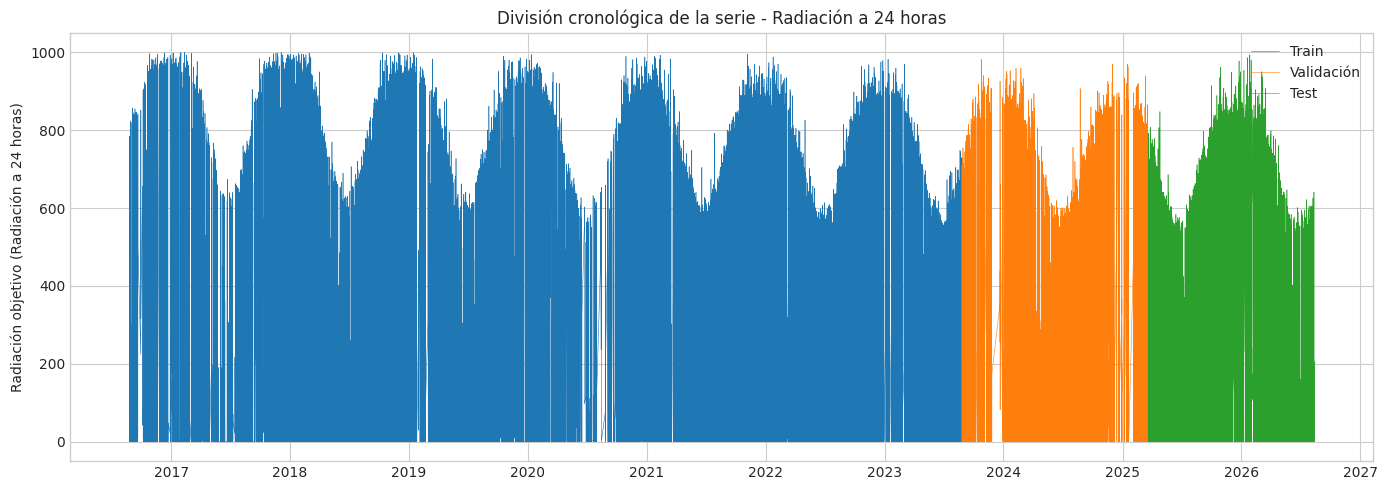

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[24h] Objetivo: radiacion_t_mas_96 | Cantidad de predictores: 32
AutoML progress: |
09:30:31.798: Project: AutoML_1_20260927_93031
09:30:31.799: Cross-validation disabled by user: no fold column nor nfolds > 1.
09:30:31.799: Setting stopping tolerance adaptively based on the training frame: 0.00216968239107417
09:30:31.799: Build control seed: 42
09:30:31.799: training frame: Frame key: AutoML_1_20260927_93031_training_Key_Frame__upload_8def49c5e4a41b4e745709d37090407b.hex    cols: 33    rows: 212426  chunks: 14    size: 23321896  checksum: 1628642139031190752
09:30:31.799: validation frame: Frame key: Key_Frame__upload_bb2268ec1af53af037c13ae6bc6d48ba.hex    cols: 33    rows: 45520  chunks: 3    size: 490

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


███████████████████████████████████████████████████████| (done) 100%
[24h] Métricas:


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,MAE,RMSE,R2,MAPE_sin_ceros_pct
test_completo,49.578125,101.563121,0.833694,120.101756
radiacion_mayor_20,109.150761,150.560363,0.619361,69.574960


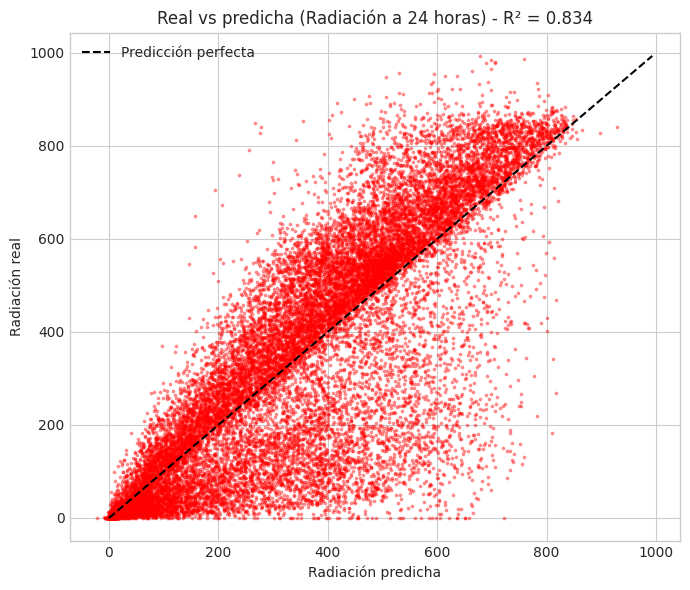

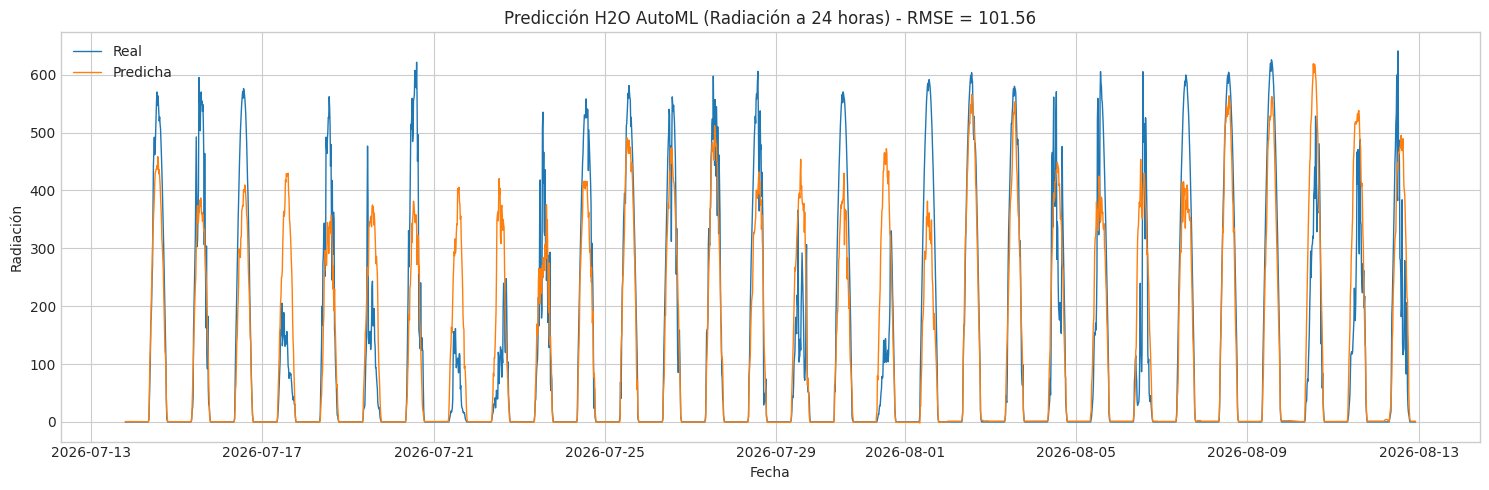

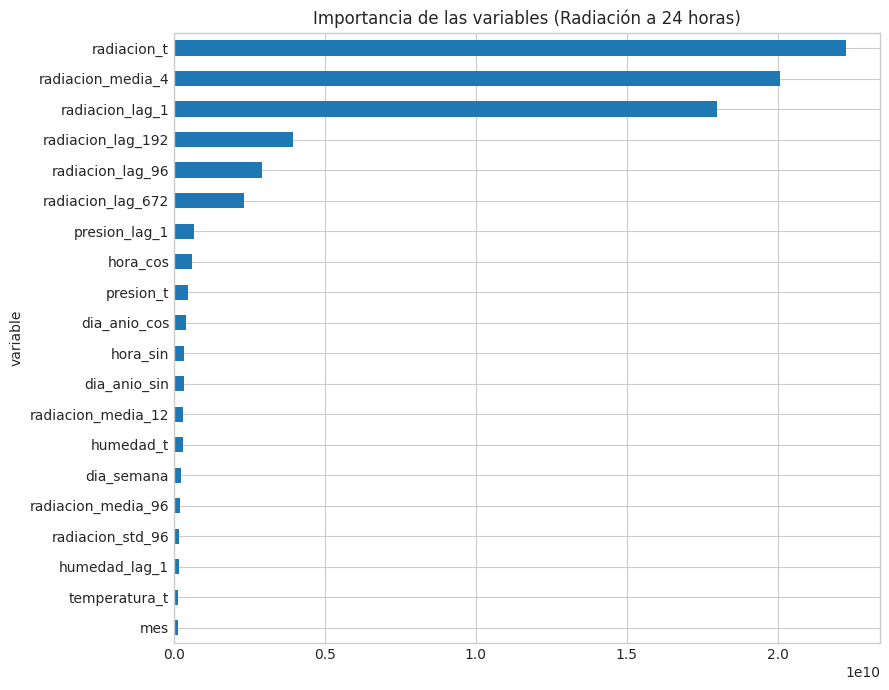

[24h] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion/24h/modelos/GBM_2_AutoML_1_20260927_93031


In [16]:
resultado_24h = entrenar_evaluar_horizonte(96, '24h', 'Radiación a 24 horas')

## 13. Ejecución — pronóstico a 1 semana

672 pasos de 15 minutos hacia adelante.

=== Horizonte: Radiación a 1 semana (672 pasos de 15 min) ===
[7d] Filas utilizables: 298846
[7d] Entrenamiento: (209192, 33) 2016-08-25 01:00:00 2023-08-18 01:30:00
[7d] Validación: (44827, 33) 2023-08-18 01:45:00 2025-03-20 05:30:00
[7d] Prueba: (44827, 33) 2025-03-20 05:45:00 2026-08-05 22:15:00


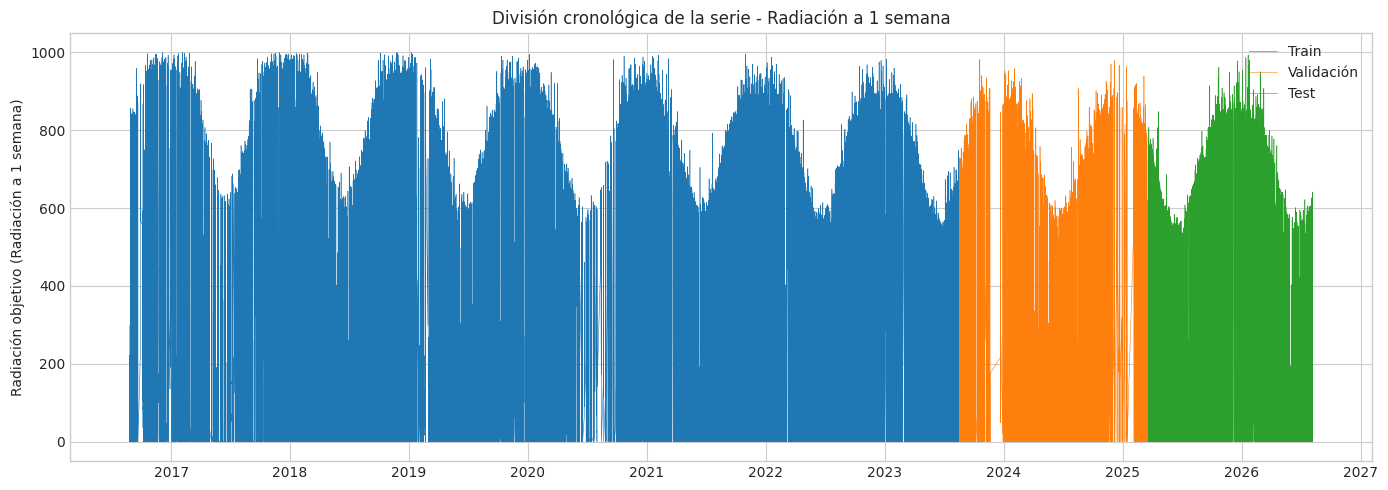

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[7d] Objetivo: radiacion_t_mas_672 | Cantidad de predictores: 32
AutoML progress: |
09:32:58.31: Project: AutoML_2_20260927_93258
09:32:58.31: Cross-validation disabled by user: no fold column nor nfolds > 1.
09:32:58.31: Setting stopping tolerance adaptively based on the training frame: 0.0021863891523967094
09:32:58.31: Build control seed: 42
09:32:58.31: training frame: Frame key: AutoML_2_20260927_93258_training_Key_Frame__upload_a43005a8d080062b7c3284d1acef4775.hex    cols: 33    rows: 209192  chunks: 14    size: 22870508  checksum: -3288832806662966890
09:32:58.31: validation frame: Frame key: Key_Frame__upload_8263d771f515aefc31b80f1d6f074d4a.hex    cols: 33    rows: 44827  chunks: 3    size: 482670

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


███████████████████████████████████████████████████████| (done) 100%
[7d] Métricas:


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,MAE,RMSE,R2,MAPE_sin_ceros_pct
test_completo,53.479648,107.219463,0.815424,162.182984
radiacion_mayor_20,116.147354,157.625117,0.582644,78.570492


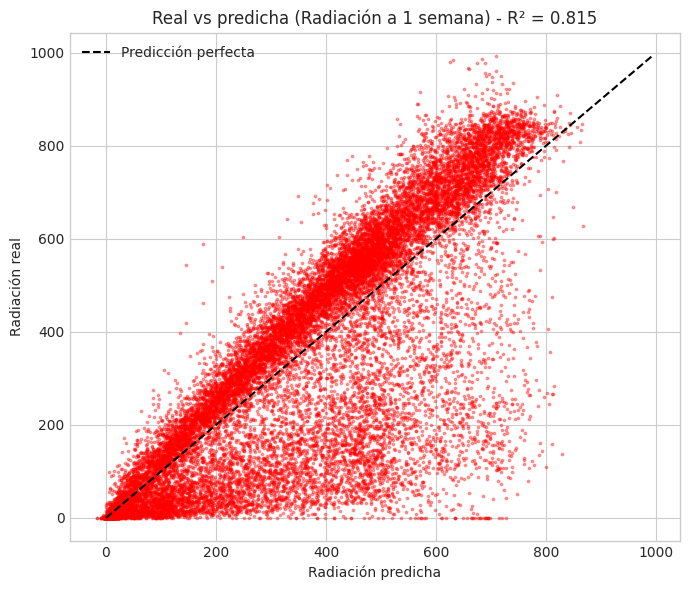

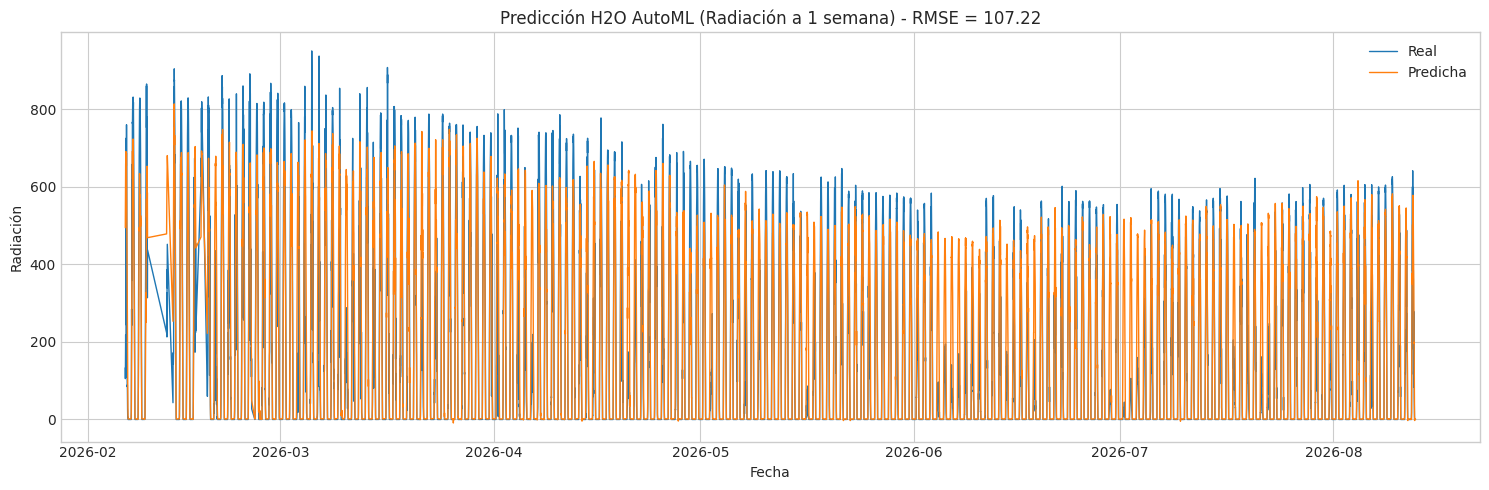

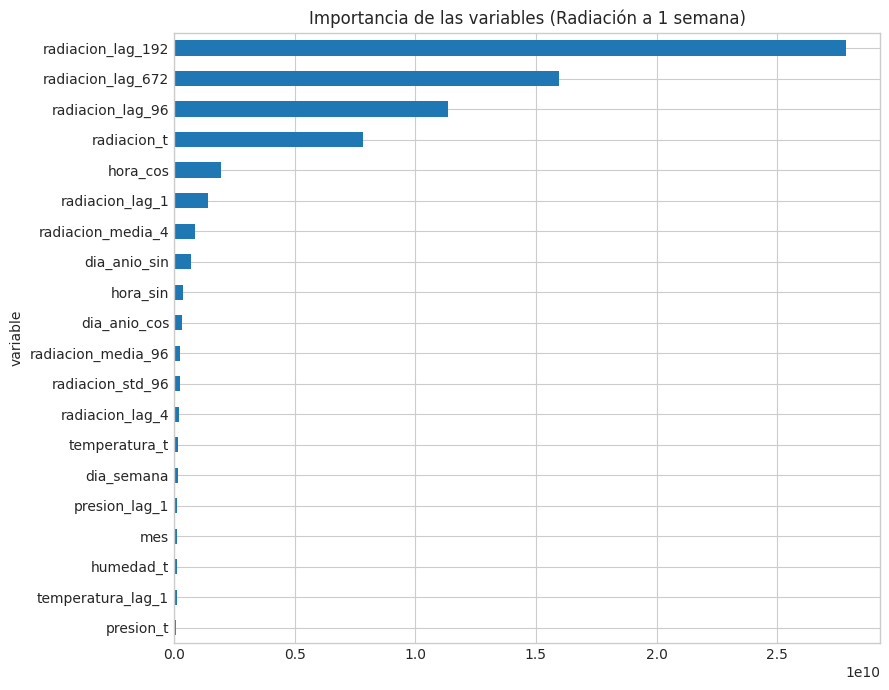

[7d] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion/7d/modelos/GBM_2_AutoML_2_20260927_93258


In [17]:
resultado_7d = entrenar_evaluar_horizonte(672, '7d', 'Radiación a 1 semana')

## 14. Comparación de métricas entre horizontes

In [18]:
tabla_comparativa = pd.DataFrame([resultado_24h, resultado_7d]).set_index('horizonte')
tabla_comparativa.to_csv(os.path.join(BASE_RESULTADOS, 'comparacion_horizontes.csv'))
tabla_comparativa

,pasos_15min,modelo_ganador,MAE,RMSE,R2,MAPE_sin_ceros_pct
horizonte,,,,,,
24h,96,GBM_2_AutoML_1_20260927_93031,49.578125,101.563121,0.833694,120.101756
7d,672,GBM_2_AutoML_2_20260927_93258,53.479648,107.219463,0.815424,162.182984


## 15. Cierre de H2O
Ejecutar esta celda cuando ya no se utilizará el clúster H2O.

In [19]:
h2o.cluster().shutdown(prompt=False)

H2O session _sid_8ac3 closed.
